In [2]:
import copy
import numpy as np
from pathlib import Path
import cv2
import torch
import torch.nn.functional as f
from matplotlib import pyplot as plt
import pandas as pd
from torchvision import datasets,transforms
from torch.utils.data.dataloader import DataLoader
from torch.utils.data import random_split
from torchvision.utils import make_grid
from tqdm import tqdm
import math
from torch.utils.data import Subset
import time

In [3]:
!pip uninstall -y cnn-internals
!pip install  --no-cache-dir  git+https://github.com/LoayMohamedAhmed/Cifar-training-with-CNN.git

  Cloning https://github.com/LoayMohamedAhmed/Cifar-training-with-CNN.git to /tmp/pip-req-build-13bfmvz3
  Running command git clone --filter=blob:none --quiet https://github.com/LoayMohamedAhmed/Cifar-training-with-CNN.git /tmp/pip-req-build-13bfmvz3
  Resolved https://github.com/LoayMohamedAhmed/Cifar-training-with-CNN.git to commit 39381e632724ef45a5f4fbcd6e5f284306432a62
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for cnn_internals: filename=cnn_internals-0.1-py3-none-any.whl size=16828 sha256=42f04ae9b4451af57367b6b91add4e1b69ace711f3a4066a2f62bb0067d78020
  Stored in directory: /tmp/pip-ephem-wheel-cache-iw7687g0/wheels/9a/43/44/17c731de8c5a36b9ab2630d16fab76de143e908a29ca98e937
Successfully built cnn_internals


In [4]:
from Src.layers import ReLU,BatchNorm2d,Dropout, Linear, Softmax, Flatten
from Src.Conv import Conv2d, Pooling2d
from Src.optim import Adams_W, LR_schedule, cross_entropy_Loss, total_loss_accur, max_lr_finder
from Src.containers import Sequential
from Src.models.LeNet import LeNet_arch
from Utils.diognstics import plot_gradient_flow, gradient_ascent, dead_percentage_hook, senity_check
from Tracking.visualization import visualize_image, display_layer_out
from Src.engine import Train_engine

# Layers
register_forward_hook() method must be implemented in each layer becasue it allow us to control the input and the output of the layer once the forwad pass complete, it takes a special hook function with (model,input,output) parameters where the model is the layer input is the input to that layer and output is the output of that layers, look at the implementation in **relu** to understand how it receive and excute the hook

In [ ]:
# g = torch.Generator().manual_seed(2882001)
# class Linear:
#     def __init__(self, in_dim , out_dim , bias = True):
#         self.W = torch.randn((in_dim , out_dim), generator = g)*(2/in_dim)**0.5
#         self.b = torch.zeros(out_dim) if bias else None
#         self._hook_id = 0
#         self._forward_hooks ={}

#     def __call__(self,X):
#         self.out = X @ self.W
#         if self.b is not None:
#             self.out+= self.b
#         for hook_id , hook_fn in self._forward_hooks.items():
#             hook_result = hook_fn(self, X, self.out)
#             if hook_result is not None:
#                 self.out = hook_result
#         return self.out
    
#     def parameters(self):
#         return {'W':self.W} | ({'b':self.b} if self.b is not None else {})

#     def register_forward_hook(self, hook_fn):
#         handle_id = self._hook_id
#         self._forward_hooks[self._hook_id] = hook_fn
#         self._hook_id += 1
#         return handle_id
    
        
# #-------------------------------------------------------------------
# class ReLU:
#     def __init__(self):
#         # construct a dic that hold all hooks applied to that layer
#         self._forward_hooks = {}
#         self._hook_id = 0
        
#     def __call__(self,Z):
#         #self.out = torch.maximum(torch.tensor(0.0),Z)
#         self.out = torch.maximum(0.001*Z,Z)
#         # loop over each hook and execute it
#         for hook_id , hook_fn in self._forward_hooks.items():
#             hook_result = hook_fn(self, Z, self.out)
#             # overwrite the output if the hook was used to alter the output
#             if hook_result is not None:
#                 self.out = hook_result
#         return self.out
        
#     def parameters(self):
#         return {}
        
#     # this function responsible for receiving hooks and assign them
#     # to that layer and return a handle if you determine todelete 
#     # the hook later
#     def register_forward_hook(self,hook_fn):
#         handle_id = self._hook_id
#         self._forward_hooks[self._hook_id] =hook_fn
#         self._hook_id+=1
#         return handle_id
        
# #-------------------------------------------------------------------
# class Flatten:
#     def __call__(self,X):
#         self.out = X.view(X.shape[0],-1)
#         return self.out
#     def parameters(self):
#         return {}
# #--------------------------------------------------------------------
# class Softmax:
#     def __init__(self):
#         # construct a dic that hold all hooks applied to that layer
#         self._forward_hooks = {}
#         self._hook_id = 0
        
#     def __call__(self,logits):
#         self.out = f.softmax(logits,dim=1)
#         for hook_id , hook_fn in self._forward_hooks.items():
#             hook_result = hook_fn(self, X, self.out)
#             if hook_result is not None:
#                 self.out = hook_result
#         return self.out
        
#     def parameters(self):
#         return {}

#     def register_forward_hook(self, hook_fn):
#         handle_id = self._hook_id
#         self._forward_hooks[self._hook_id] = hook_fn
#         self._hook_id += 1
#         return handle_id
# #------------------------------------------------------------------
# class Dropout:
#     def __init__(self,dr_rate):
#         self.rate = dr_rate
#         self.state = 1
#         self._forward_hooks = {}
#         self._hook_id = 0

#     def __call__(self , X):
#         if self.state:
#             self.mask = torch.rand_like(X)
#             self.out = X * self.mask/(1-self.rate)
#         else:
#             self.out = X
#             self.state = 1

#         for hook_id , hook_fn in self._forward_hooks.items():
#             hook_result = hook_fn(self, X, self.out)
#             if hook_result is not None:
#                 self.out = hook_result
#         return self.out
    
#     def parameters(self):
#         return {}

#     def register_forward_hook(self, hook_fn):
#         handle_id = self._hook_id
#         self._forward_hooks[self._hook_id] = hook_fn
#         self._hook_id += 1
#         return handle_id

# #------------------------------------------------------------------------------
# class BatchNorm2d:
#     def __init__(self,channel_num,eps =1e-8,momentum = 0.999):
#         self.state = 1
#         self.B = momentum
#         self.gama = torch.ones((1,channel_num,1,1))
#         self.beta = torch.zeros((1,channel_num,1,1))
#         self.eps = eps
#         self.RAM = 0  # running average mean
#         self.RAS = 0  # running average standared deviation
#         self._forward_hooks = {}
#         self._hook_id = 0
        
#     def __call__(self,X):
#             m = X.shape[0]
#             #dim = [c for c in range(len(X.shape))]
#             if self.state:
#                 self.mean = X.mean(dim = (0,2,3), keepdim = True)
#                 self.std = X.std(dim = (0,2,3), keepdim = True)
#                 with torch.no_grad():
#                     self.RAM = self.B * self.RAM + (1-self.B) * self.mean
#                     self.RAS = self.B * self.RAS + (1-self.B) * self.std
#             else:
#                 self.mean = self.RAM
#                 self.std = self.RAS
#                 self.state = 1
#             self.normalized = (X-self.mean)/(self.std + self.eps)
#             self.out = self.normalized * self.gama + self.beta
#             for hook_id , hook_fn in self._forward_hooks.items():
#                 hook_result = hook_fn(self, X, self.out)
#                 if hook_result is not None:
#                     self.out = hook_result
#             return self.out

#     def parameters(self):
#         return {'gama':self.gama , 'beta':self.beta}

#     def register_forward_hook(self, hook_fn):
#         handle_id = self._hook_id
#         self._forward_hooks[self._hook_id] = hook_fn
#         self._hook_id += 1
#         return handle_id
# #------------------------------------------------------------------------------
# class Sequential:
#     def __init__(self, *layers):
#         self.layers = list(layers)
#         self.state = 1
#         self.module_names = {}
#         for p in self.parameters().values():
#             p.requires_grad = True
#         self.layer_names()
#         best_param = copy.deepcopy(self.parameters())

#     def load(self,param):
#         if isinstance(param,(str,Path)):
#             # map location tells pytorch to load into the CPU even if the data saved from GPU
#             param = torch.load(param, map_location = 'cpu')
#         current_param = self.parameters()
#         with torch.no_grad():
#             for key , tensor in param.items():
#                 current_param[key].copy_(tensor)

#     def layer_names(self):
#         layers = {}
#         for layer in self.layers:
#             name = layer.__class__.__name__
#             if name in layers.keys():
#                 layers[name]+=1
#             else:
#                 layers[name] = 1
#             self.module_names[id(layer)] = name +' '+ str(layers[name])
                
#     def train(self):
#         self.state = 1
        
#     def eval(self):
#         self.state = 0
        
#     def __call__(self,X):
#         self.out = X
#         for layer in self.layers:
#             if not self.state and isinstance(layer, (Dropout, BatchNorm2d )):
#                layer.state = 0
#             self.out = layer(self.out)
#         return self.out  
        
#     def parameters(self):
#         # this function assign each layer weight with a layer index+layer weight
#         # 0.W , 00.W, 00.b for hierachical structure 
#         param = {}
#         def param_discover(module,prefix = ""):
#             if isinstance(module , Sequential):
#                 for i , layer in enumerate(module.layers):
#                     param_discover(layer,f"{prefix}{i}.")
#             else:
#                 for k, val in module.parameters().items():
#                     param[f"{prefix}{k}"] = val 
#         param_discover(self)          
#         return param
    
#     def summary(self,input_size):
#         total_param = 0
#         summary = pd.DataFrame({'Layer_type':[],'output shape':[],'#parameters':[]})
#         X = torch.rand((1,*input_size))
#         self.eval()
#         for layer in self.layers:
#             with torch.no_grad():
#                 if isinstance(layer,BatchNorm2d):
#                     layer.state = 0
#                 X = layer(X)
#             no_param = int(np.sum([p.numel() for p in layer.parameters().values()]))
#             layer_type = self.module_names[id(layer)]
#             dim = ' , '.join([str(X.shape[i]) for i in range(1,len(X.shape))])
#             out_shape = '(nan , ' + f'{dim}' +' )'
#             summary.loc[len(summary)] = [ layer_type ,out_shape,no_param]
#             total_param+= no_param
#         self.train()
#         display(summary)
#         print( f"total number of parameters: {total_param}")

#     def EarlyStopping(self, patience_per):
#         best_val_loss = np.inf
#         stop = False
#         remaining_period = patience_per
#         def early_stopping(current_val_loss):
#             # in nested function if i don't set nonlocal identifire berfore the nested variable
#             # it will treat them as local ones
#             nonlocal best_val_loss, stop, remaining_period
#             if current_val_loss < best_val_loss:
#                 best_val_loss = current_val_loss
#                 self.best_param = copy.deepcopy(self.parameters())
#                 remaining_period = patience_per
#             else:
#                 remaining_period -= 1
#                 if remaining_period == 0:
#                     stop = True
#             return stop, best_val_loss 
#         return early_stopping

In [ ]:
# # convolution implementation
# class Conv2d:
#     def __init__(self, num_filters, filter_size, in_channels ,padding = 0, stride = 1, bias = True):
#         if isinstance(filter_size, int):# kernel width and hight
#             self.Kh = self.Kw = filter_size
#         else:
#             self.Kh, self.Kw = filter_size 
#         self.Kd = in_channels #kernel depth
#         self.pad, self.str = padding, stride
#         self.fan_in = self.Kw * self.Kh * self.Kd
#         self.W = torch.randn((num_filters , self.fan_in), generator= g)*(2/self.fan_in)**0.5 #(f,C*h*W)
#         self.b = torch.zeros((num_filters,1)) if bias else None
        
        
    
#     def __call__(self,X):
#         GEMM,out_H,out_W = self.im2col(X)
#         out_flat = self.W @ GEMM
#         if self.b is not None:
#             out_flat += self.b
            
#         out = out_flat.reshape(self.W.shape[0],X.shape[0],out_H,out_W).permute(1,0,2,3) # shape(N,cout,H,W)
#         return out

#     def parameters(self):
#         return {'W':self.W} | ({'b':self.b} if self.b is not None else {})

#     def im2col(self,X):
#         pad = (self.pad,)*4
#         X_pad = f.pad(X, pad, value = 0)
#         N,C,H,W = X_pad.shape
#         out_H = (H - self.Kh)//self.str +1
#         out_W = (W - self.Kw)//self.str +1
#         Device = X.device
#         # construct the offset of the kernel locally
#         # for 3*3 offset is i = [0,0,0, 1,1,1, 2,2,2] j = [0,1,2, 0,1,2, 0,1,2]
#         #repeat_interleave is the same as repeat in numpy
#         i_offset = torch.arange(self.Kh, device= Device).repeat_interleave(self.Kw) # shape of (patch size)
#         j_offset = torch.arange(self.Kw, device= Device).repeat(self.Kh) # repeat is the same as tile in numpy

#         # generate the starting point for each patch
#         i_start = torch.arange(out_H, device= Device).repeat_interleave(out_W) * self.str # shape of (out_H * out_W) = number of patches
#         j_start = torch.arange(out_W, device= Device).repeat(out_H) * self.str

#         # generate the indices for each patch
#         i_indices = i_start.reshape(-1,1) + i_offset.reshape(1,-1) # (1,number of patches,patch size)
#         j_indices = j_start.reshape(-1,1) + j_offset.reshape(1,-1)

#         # extract the patches from the data
#         # S is the patch size, p is the number of patches, C number of channels, N is the batch size
#         col = X_pad[:,:,i_indices,j_indices] # shape (N,C,P,S)
#         col = col.permute(1,3,0,2) # shape(C,S,N,P)
#         # construct GEMM "general matrix multiplication"
#         # Using .contiguous() is sometimes required after .permute() before .reshape()
#         # to ensure that the data stored in conteguous blocks
#         col =  col.contiguous().reshape(C * self.Kw * self.Kh, -1) #to have shape (C*S,N*P)
#         return col,out_H, out_W

# class Pooling2d:
#     def __init__(self, kernel_size ,pool_type, stride = None, padding = 0):
#         if isinstance(kernel_size, int):
#             self.Kh = self.Kw = kernel_size
#         else:
#             self.Kh, self.Kw = kernel_size
#         self.ptype = pool_type
#         self.str = stride if stride is not None else kernel_size
#         self.pad = padding

#     def parameters(self):
#         return {}

#     def __call__(self,X):
#         if self.ptype == 'GAP':
#             return X.mean(dim = (-2,-1))
#         N,C,H,W = X.shape
#         X_pad = f.pad(X,(self.pad,)*4,value = 0)
#         out_H = (H + 2*self.pad - self.Kh)//self.str + 1
#         out_W = (W + 2*self.pad - self.Kw)//self.str + 1
#         device = X.device
#         i_offset = torch.arange(self.Kh, device= device).repeat_interleave(self.Kw)
#         j_offset = torch.arange(self.Kw, device= device).repeat(self.Kh)

#         i_start = torch.arange(out_H, device= device).repeat_interleave(out_W) *self.str
#         j_start = torch.arange(out_W, device= device).repeat(out_H) * self.str

#         i_indices = i_start.reshape(-1,1) + i_offset.reshape(1,-1)
#         j_indices = j_start.reshape(-1,1) + j_offset.reshape(1,-1)

#         col = X_pad[:, : , i_indices,j_indices] # shape(N,C,P,S)
#         if self.ptype == 'MAX':
#             out = (col.max(dim =-1))[0].reshape(N,C,out_H,out_W)
#         elif self.ptype == 'AVG':
#             out = (col.mean(dim = -1)).reshape(N,C,out_H,out_W)
#         return out


# Load data

In [ ]:
# adda transformation to data when loading it
val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean = (0.4915, 0.4824, 0.4469),
        std = (0.2469, 0.2433, 0.2615)
    )
])
tr_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.RandomCrop(32,4), # create a random translation to break the location correlation
    #transforms.RandomResizedCrop(32,scale=(0.8,1)), # zoom in effect
    transforms.RandomHorizontalFlip(p=0.5), # a probability of 0.5 that the image is floped
    transforms.RandomRotation(degrees=(-10,10),interpolation= transforms.InterpolationMode.BILINEAR,fill=0,expand= False),
    transforms.ColorJitter(brightness = 0.2, contrast = 0.2, saturation = 0.2),
    transforms.Normalize(
        mean = (0.4915, 0.4824, 0.4469),
        std = (0.2469, 0.2433, 0.2615)
    )
])
train_data = datasets.CIFAR10(root='./data', train = True,download = True,transform = tr_transform)
val_data = datasets.CIFAR10(root='./data', train = True,download = True,transform = val_transform)

 10%|█         | 17.5M/170M [00:48<06:56, 367kB/s]

In [ ]:
# devide the data into train and validation sets
g = torch.Generator().manual_seed(2882001)
data_len = len(train_data)
train_size = int(0.8 * data_len)
val_size = data_len - train_size
#create shuffle indices 
indices = torch.randperm(data_len, generator = g)# craete a shuffeld list of indices from 0 to data_len-1
train_idx = indices[:train_size] # list of training indices
val_idx = indices[train_size:]  # list of validation indices
data_tr, data_val = Subset(train_data , train_idx), Subset(val_data , val_idx)
#data_tr , data_val =random_split(val_data,[train_size,val_size],generator = g)

In [ ]:
data_tr_dl = DataLoader(data_tr, batch_size = 64, shuffle = True)
data_val_dl = DataLoader(data_val, batch_size = 64, shuffle = True)

In [ ]:
#next(iter(data_tr_dl))[0][0].shape
len(data_val_dl)

# construct model

In [ ]:
# # helper functions
# #self.Update_to_Weight_Ratio[idx].append(((-update_step).std()/p.std()).log10().item())

# class cross_entropy_Loss:
#     def __init__(self, weights , lambda_l1 = None,lambda_l2 = None ):
#         self.weights = weights
#         self.l1 = lambda_l1 
#         self.l2 = lambda_l2
#         self.lasso = True if self.l1 is not None else False
#         self.ridge = True if self.l2 is not None else False
        
#     def compute(self, logits , classes):
#         cost_W = f.cross_entropy(logits,classes)
#         lasso_penality = 0 if not self.lasso else self.l1 * sum(torch.abs(W).sum() for W in self.weights.values())
#         ridge_penality = 0 if not self.ridge else self.l2 * sum((W**2).sum() for W in self.weights.values())
#         loss = cost_W + ridge_penality + lasso_penality 
#         return loss

# def total_loss_accur(model , data):
#     total_loss = 0.0
#     total_images = 0
#     correct = 0
#     model.eval()
#     with torch.no_grad():
#         for images,classes in data:
#              logits = model(images)
#              loss = f.cross_entropy(logits,classes,reduction='sum')
#              pred = torch.argmax(logits,dim = 1)
#              correct += (pred == classes).sum().item()
#              total_loss+=loss.item()
#              total_images += classes.shape[0]
#         accuracy = 100 * correct / total_images
#         avg_loss = total_loss / total_images
#     return avg_loss, accuracy

# class Adams_W:
#     def __init__(self,params, B1=0.9 , B2 = 0.999, LR = 1e-3  ,epsilon = 1e-7, weight_decay = 0 ):
#         self.LR , self.B1 , self.B2, self.eps =  LR, B1, B2 , epsilon
#         self.weight_decay = weight_decay
#         self.state = {}
#         if isinstance(params, list):
#             self.groups = params
#         else:
#             self.groups = [{'params': params }]
            
#         self.construct_group_params()
#         # compute the ratio between the weight update step size and the current weight
#         self.Update_to_Weight_Ratio = []
       
#     def construct_group_params(self):
#         for group in self.groups:
#             group['lr'] = group.get('lr', self.LR)
#             group['betas'] = group.get('betas', (self.B1, self.B2))
#             group['eps'] = group.get('eps', self.eps)
#             group['weight_decay'] = group.get('weight_decay', self.weight_decay)
#             for p in group['params'].values():
#                 self.Update_to_Weight_Ratio.append([])
#                 self.state[id(p)] = {
#                     'step':1,
#                     'mt': torch.zeros_like(p),
#                     'st': torch.zeros_like(p)
#                 }
#     def __call__(self):
#         with torch.no_grad():
#             idx = 0 
#             for group in self.groups:
#                 (B1 ,B2), lr, eps = group['betas'], group['lr'], group['eps']
#                 weight_decay = group['weight_decay']
#                 for p in group['params'].values():
#                     # to not update the frozen paramters
#                     if p.grad is None:
#                         continue
#                     t = self.state[id(p)]['step']
#                     self.state[id(p)]['step'] += 1
#                     mt = self.state[id(p)]['mt']
#                     st = self.state[id(p)]['st']
                        
#                     # don't use mt= ..... because pytorch creat-
#                     # -new tensor of the rsult and make mt point at them use .copy instead-
#                     # that will compute the values and set a copy of them inside each mt and st tensor inplace
#                     mt.copy_( B1 * mt + (1 - B1) * p.grad)
#                     st.copy_( B2 * st + (1 - B2) * p.grad.pow(2))
                    
#                     # apply correction bias to both mt and st because you intialize them with 0 so they
#                     #   will force the network to take artificially tiny baby step.
#                     #      This is called being "biased towards zero."
#                     # the correction scale up the momentum at intial epochs and by the time t grows
#                     #  its effect disappear entirly because the B**t decreases hardly so (1-B**t) will
#                     #                be almost 1
#                     mt_hat = mt/(1 - B1**t)
#                     st_hat = st/(1 - B2**t)
                    
#                     update_step = lr * (mt_hat/(torch.sqrt(st_hat)+ eps) + p * weight_decay)
#                     self.Update_to_Weight_Ratio[idx].append(((-update_step).std()/p.std()).log10().item())
#                     p.sub_(update_step)
#                     idx += 1


# class LR_schedule:
#     def __init__(self, optimizer, algo_type, epochs, decay_rate = None, step_size = None, warm_up = 5):
#         self.optimizer = optimizer
#         self.warmup_lr = {}
#         self.decay_rate, self.step_size = decay_rate, step_size
#         self.algo_type, self.warm_up, self.epochs = algo_type, warm_up, epochs
#         self.base_lr = [group['lr'] for group in self.optimizer.groups]
        
#         for i, group in enumerate(self.optimizer.groups):
#             max_lr = self.base_lr[i]
#             min_lr = max_lr/10 if algo_type != 'cosin' else 1e-6
#             self.warmup_lr[i] = np.linspace(min_lr ,max_lr, warm_up)

#     def step(self, epoch):
#         sched_ = self.sched()
#         for i, group in enumerate(self.optimizer.groups):
#             max_lr = self.base_lr[i]
#             min_lr = max_lr/10 if self.algo_type != 'cosin' else 1e-6
#             if epoch < self.warm_up:
#                 new_lr = self.warmup_lr[i][epoch]
#             else:
#                 new_lr =  sched_(max_lr ,epoch, min_lr)
#             group['lr'] = new_lr

#     def set_lr(self,lr):
#         for group in self.optimizer.groups:
#            group['lr'] =  lr

    
#     def sched(self): 
#         def step_decay(max_lr,epoch , min_lr):
#             out = max_lr * self.decay_rate**math.floor((epoch-self.warm_up)/self.step_size)
#             return out
    
#         def exponential(max_lr , epoch , min_lr):
#             out = max_lr * math.exp(-self.decay_rate * (epoch-self.warm_up))
#             return out
            
#         def cosin_annealing(max_lr , epoch , min_lr):
#             out = min_lr + 0.5* (max_lr - min_lr) * (1+math.cos(math.pi*(epoch-self.warm_up)/(self.epochs-self.warm_up)))
#             return out

#         if self.algo_type == 'step decay':
#             return step_decay
#         elif self.algo_type == 'exponential':
#             return exponential
#         elif self.algo_type == 'cosin':
#             return cosin_annealing
#         else:
#             raise ValueError(f"Unknown algo_type: {self.algo_type}")
    
        


In [ ]:
batch_sizes = [2**x for x in range(5,11)]
batch = batch_sizes[1]
hidden_sizes = [100*x for x in range(1,10)]
LRs = np.linspace(-7,0,len(data_tr)//batch)
lr_algo = ['step decay','exponential','cosin']
epochs = 50
iterations = len(data_tr)//batch
lambdas = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2]
drop_rates = [0.1 * x for x in range(1,10)]


## architectures
i will try different architectures blocks for backbone
sequential **(LeNet-5)**
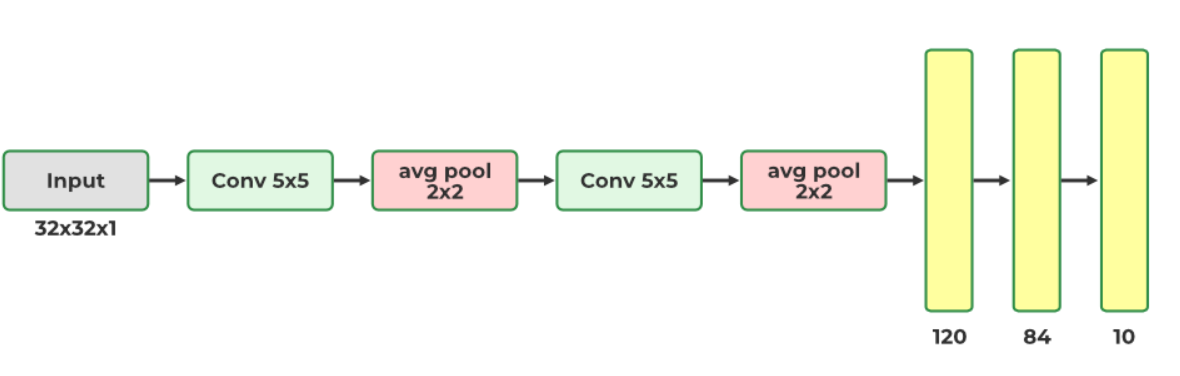


In [ ]:
# construct the model
model = Sequential(
    Conv2d(num_filters = 32, filter_size = (5,5), in_channels=3,padding = 2, bias=False),
    BatchNorm2d(32,momentum = 0.999),
    ReLU(),
    Pooling2d(kernel_size = 2 ,pool_type = 'MAX'),
    Conv2d(num_filters = 64, filter_size = (5,5), in_channels=32,padding = 1,bias=False), 
    BatchNorm2d(64,momentum = 0.999),ReLU(),
    Pooling2d(kernel_size = 2 ,pool_type = 'MAX'),
    Flatten(),
    Linear(in_dim= 7*7*64, out_dim =120),ReLU(),
    Linear(in_dim= 120 , out_dim = 84), ReLU(),
    Linear(in_dim= 84 , out_dim = 10)
)
# construct the optimizer and the lr schedual
parameters = model.parameters()
weight_decay = lambdas[1]
warmup,algo_type = 5, lr_algo[2]
adams = Adams_W(parameters, LR = 0.0018,weight_decay = weight_decay)
lr = LR_schedule(adams, algo_type, epochs, warmup )
CE_loss = cross_entropy_Loss(parameters)
train_engine = Train_engine(model, adams,CE_loss)
#lr.set_lr(max_lr_finder(LRs , data_tr_dl , train_engine, lr))

SM = Softmax()
# decrease the weight of the last linear layer so that the weight
# not become biased toweard some specific class
with torch.no_grad():
    model.layers[-1].W *=0.01

path2 = "/kaggle/input/models/loaymohamed432/lenet-5last/pytorch/default/1/weights (3).pt"
model.load(path2)
eraly_stop = model.EarlyStopping(patience_per=10)

display(model.summary((3 , 32 , 32)))

In [ ]:
# claculate the l2 norm of the gradient of the paramters to check if the gradient of the
# earlier layers drop in order of magnitude compared to the final layers gradients or explode in the earlier layers
grad_2norm = [[] for _ in parameters]

# define hooks to gt the percentage of the dead relu
dead_relu_percentage = {}
for module in model.layers:
    if isinstance(module, ReLU):
        name = model.module_names[id(module)]
        module.register_forward_hook(dead_percentage_hook(name, dead_relu_percentage))

In [ ]:
# single batch for sanity check 
images, classes = next(iter(data_tr_dl))
image = images[0].unsqueeze(0)

In [ ]:
def visualize_image(image_tensor , title):
    # to seprate the tensor from the computational graph, move it into cpu and finally remove the channel 0
    image_tensor = image_tensor.detach().cpu().squeeze(0) 
    # normalize the input iamge as the gradient ascent doesn't know what's the valid image looks like
    # it may result in negative values.
    image_tensor -= image_tensor.min()
    image_tensor /= image_tensor.max()
    image_tensor = image_tensor.clamp(0,1) # to ensure the range is between 0 and 1
    image_tensor = image_tensor.permute(1,2,0)
    plt.imshow(image_tensor)
    plt.title(title)

In [ ]:
from PIL import Image
import requests
from io import BytesIO
url = "https://th.bing.com/th?id=OIF.46h5KQQ4U%2BXc%2B0kxrWOGsA&r=0&rs=1&pid=ImgDetMain&o=7&rm=3"
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean = (0.4915, 0.4824, 0.4469),
        std = (0.2469, 0.2433, 0.2615)
    )
])
img = Image.open(BytesIO(requests.get(url).content))
X = transform(img)
visualize_image(X,'original_image')
train_data.classes[classes[0]]

In [ ]:
# training loop
losses = []
step = 0
lrs = []
avg_dead_ReLU = []
training_criteria = {'loss':[],'accur': []}
val_criteria = {'loss':[],'accur': []}

for epoch in range(epochs):
    accum_loss = 0
    tr_acc = 0
    dead_ReLU = []
    for images, classes in tqdm(data_tr_dl , desc = 'iterations'):
        lr.step(epoch)
        loss, logits = train_engine.step(images , classes)
        accum_loss += loss
        
        #calculate the l2 norm of the gradients
        # calculate the dea relus 
        dead_ReLU.append(list(dead_relu_percentage.values()))
        for i, p in enumerate(parameters.values()):
            with torch.no_grad():
                grad_2norm[i].append(p.grad.norm(2).item())
        
        # measure the training accuracy
        with torch.no_grad():
            pred = torch.argmax(SM(logits),dim = 1)
            tr_acc += (pred == classes).float().mean()
            
    model.eval()
    avg_dead_ReLU.append(np.mean(dead_ReLU, axis = 0))

    # training Ctriteria
    avg_tr_loss = accum_loss/len(data_tr_dl)
    avg_tr_accuracy = tr_acc/len(data_tr_dl) * 100
    training_criteria['loss'].append(avg_tr_loss)
    training_criteria['accur'].append(avg_tr_accuracy)

    # validation Criteria
    avg_val_loss, avg_val_accuracy = total_loss_accur(model,data_val_dl)
    training_criteria['loss'].append(avg_val_loss)
    training_criteria['accur'].append(avg_val_accuracy)
    
    # training reports
    print(f'epoch: {epoch+1}/{epochs} |'
          f'avg train loss: {avg_tr_loss:.4f} |' 
          f'avg val loss: {avg_val_loss:.4f}'
         )
    print(
          f'avg train accuracy: {avg_tr_accuracy:.4f} % |' 
          f'avg val accuracy: {avg_val_accuracy:.4f} %'
         )

    stop, best_val= eraly_stop(avg_val_loss)
    if stop:
        print(f"break to avoid over fitting with best val loss: {best_val}")
        model.load(model.best_param)
        break

In [ ]:
# save the weights
torch.save(model.parameters(),"weights.pt")

# Analysis

## sanity check
Before running a full epoch, you must prove the architecture can learn by training the model only on one batch for 50 or 100 itertions.
If your loss doesn't rapidly approach zero and accuracy doesn't hit 100%, you have a fundamental bug. It instantly rules out architectural bottlenecks, silent graph disconnections, or severe optimizer misconfigurations before you waste hours training.

In [ ]:
#sanity check
senity_check({'images':images, 'classes':classes},train_engine)


## Dead/Saturated Activation Tracking
track the percentage of dead neurons during the training process if 40% neurons dead :
* At the beginning: bad initialisation may kill neurons immediately.
* During training: large learning rates or weight updates may gradually kill neurons.
* Near convergence: some neurons may become permanently inactive.

In [ ]:
#track the activaion dead neuron percentage
legends =[]
avg_dead = np.array(avg_dead_ReLU)
for i in range(avg_dead.shape[1]):
    plt.plot(avg_dead[:,i])
    legends.append(f'ReLU {i+1}')
plt.legend(legends)
plt.show()

## Gradient Norm Tracking
we monitor the gradient i the backword pass, by computing the L2 norm for each layer gradient to see if the signal survive through the trip and reach the earlier layers.

If the gradient norm in your first convolutional layer drops by orders of magnitude compared to your final fully connected layer, you are experiencing vanishing gradients.

In [ ]:
# def plot_gradient_flow(model , grad_norm , iterations_per_epochs,title,x_label = '', y_label = ''):
#     grad_norm_array = np.array(grad_norm)
#     parameters_num = grad_norm_array.shape[0]
#     epochs_num = grad_norm_array.shape[1] // iterations_per_epochs

#     # truncate the gradient based on the number of iterartions per epoch to ignore the incomplete epochs where the number of iterations is smaller than the previouse epochs
#     # i do this for dynamic sampler but as i train CIFAR, it's a fixed size dataset so the number of iterations  per epoch is constant 
#     valid_length = iterations_per_epochs * epochs_num
#     grad_norm_array = grad_norm_array[:, :valid_length]
#     grad_norm_array = grad_norm_array.reshape(-1,epochs_num, iterations_per_epochs).mean(axis = 2)

#     layer_id = 1
#     param_id = 0
#     colors = plt.cm.tab20.colors
#     for layer_idx, layer in enumerate(model.layers):
#         params = layer.parameters()
    
#         if len(params) == 0:
#             continue
    
#         color = colors[layer_id % len(colors)]
    
#         for i, _ in enumerate(params):
#             # first curve gets the legend label
#             plt.plot(
#                 grad_norm_array[param_id],
#                 color=color,
#                 label=f"{layer.__class__.__name__}{layer_id}" if i==0 else None
#                 )
#             param_id += 1
#         layer_id += 1

#     plt.title(title)
#     plt.xlabel(x_label)
#     plt.ylabel(y_label)
#     plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
#     plt.tight_layout()
#     plt.grid(True, alpha=0.3)
    
plt.figure(figsize=(8, 5))
title = "Gradient Flow: L2 Norms per Layer over Epochs"
x_label = "Epochs"
y_labe = "Average Gradient L2 Norm"
plot_gradient_flow(model, grad_2norm,iterations, title)
plt.show()

## The Update-to-Weight Ratio
It measures how much the weights are actually changing relative to their current scale.
it's calculated by the ratio between the standard deviation of the weight update step and the standard deviation of the weights themselves.
The ideal ratio is typically around 10^{-3} or -3 in log scale:
* If the ratio is -1 or -2, the step size is too violent, and the network will struggle to settle into a ravine (pathological curvature).
* If the ratio is -5 or -6, the weights are barely moving, and training has effectively stalled. the gradient vanish or the learning rate is too small

In [ ]:
plt.figure(figsize=(8, 5))
title = "Gradient Flow: weight2update ratio per Layer over Epochs"
x_label = "Epochs"
y_labe = "Average weight2update ratio"
plot_gradient_flow(model, adams.Update_to_Weight_Ratio,iterations, title)
plt.show()

# Visualization

In [ ]:
# visualize the layers output
display_layer_out(layer_idx=4,model= model, image = image)

In [ ]:
# implement gradient ascent that maximize the output
# the goal is to visualize the filter structure through maximizing the output ofthat filter
# maximizing the output means that the filter found the template it searched for
img = gradient_ascent(model, 4,2,LR = 0.1,steps = 100)
visualize_image(img, 'pattern of fifth filter of the second conv layer')

In [ ]:
# plt.plot(lrs)

In [ ]:
# legends = []
# for i, layer in enumerate(model.layers):
#     if isinstance(layer,ReLU):
#         print(f'std of ReLU {i}: {layer.out.reshape(-1).std()}')
#         hy,hx = torch.histogram(layer.out,density = True)
#         plt.plot(hx[:-1].detach(),hy.detach())
#         legends.append(f'ReLU {i+1}')
# plt.legend(legends)
# plt.yscale("log")

# LeNet-5
start with LeNet-5(**avg train loss**: 0.0574 |**avg val loss**: 3.3383): **overfitting**
* no regularization technique
* Cosine annealing lr schedual with max lr 0.008
* no batch normalization
* no dropout
* relu activation.
* batch size 64
  
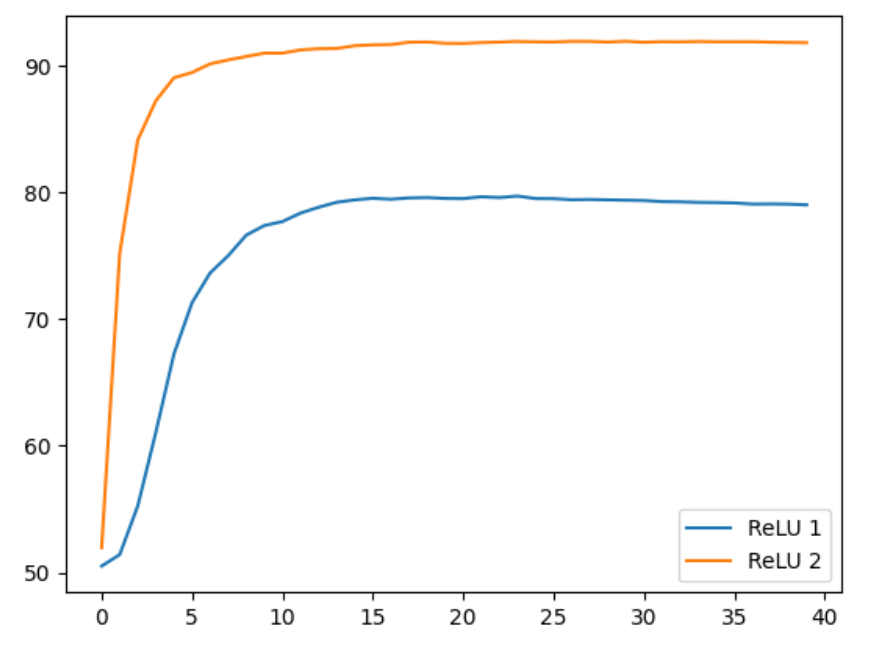

i have found from the graph of dead neurons that more of 80% of the second layer capacity is lost in the warmup phase due to the steep learning rate so i decreaes the max learning rate to the half.

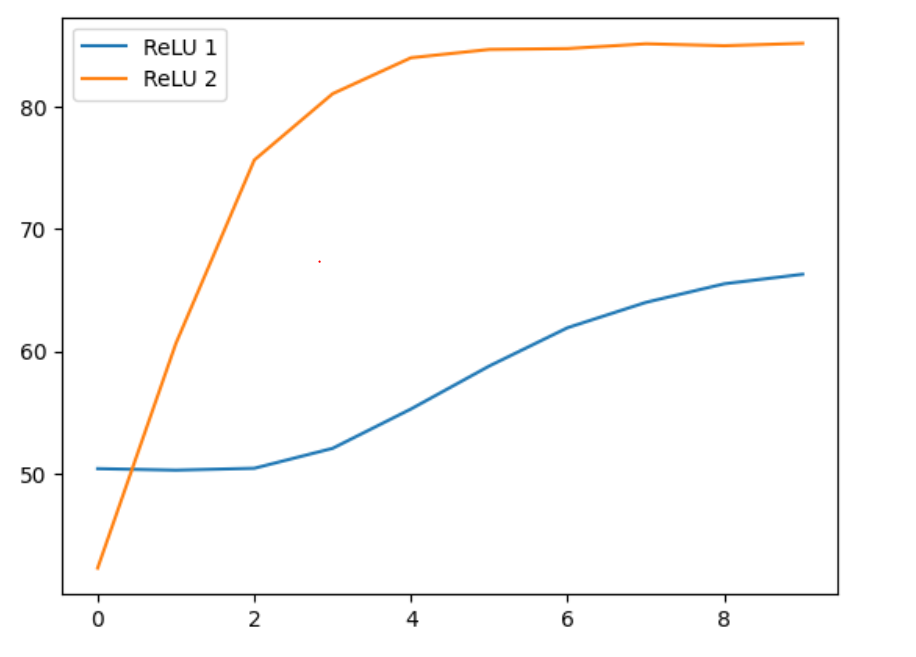
shrinking the learning rate doesn't help so it might be the violent weight update due to gradient so i will use batch normalization layer to  decrease over fitting and metigate the vanishing gradient effect.

the normal behavior is that the curve of the first layer start from 50% becasue kaiming/He inintialization make the input distribution centered around zero, but later the curve must shrink an stepdown as the weight get updated. 

<div style="display:flex; gap:10px;">
    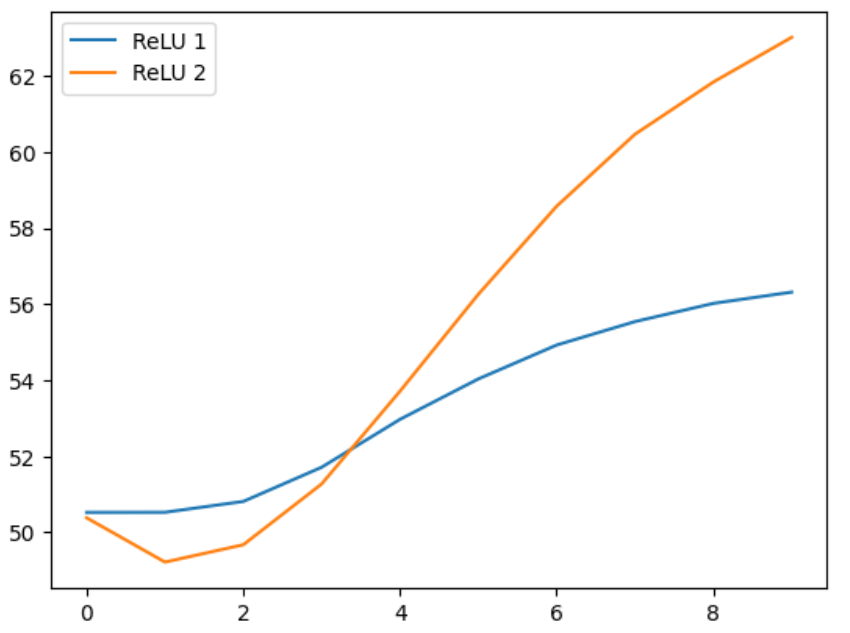
    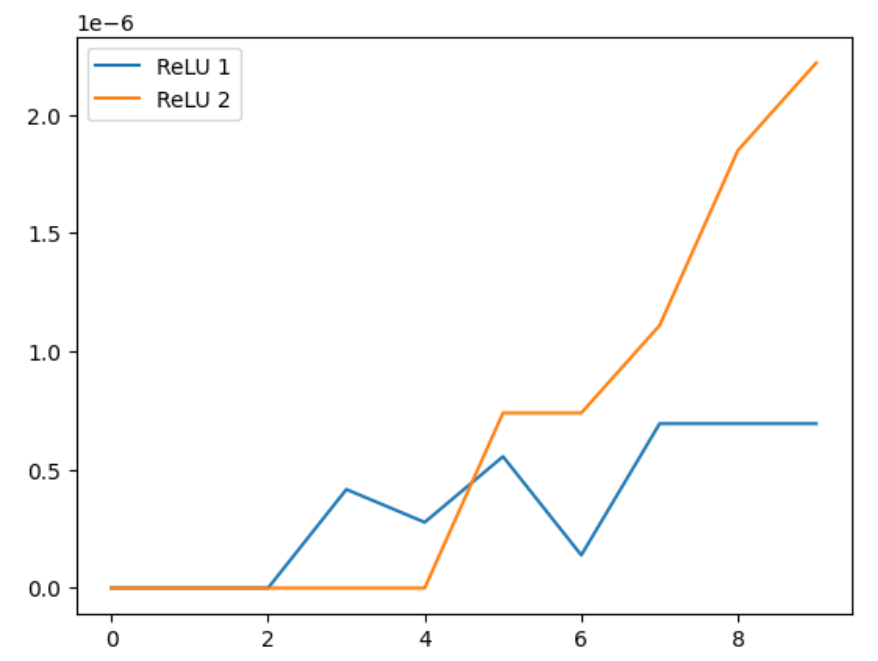
</div>

the waste in resources decrease, we may use leaky relue to give the neuron a chance to relive again.and actually it works

when i look at the gradient norm curve after we use normalization layer i found it reach the healthy state

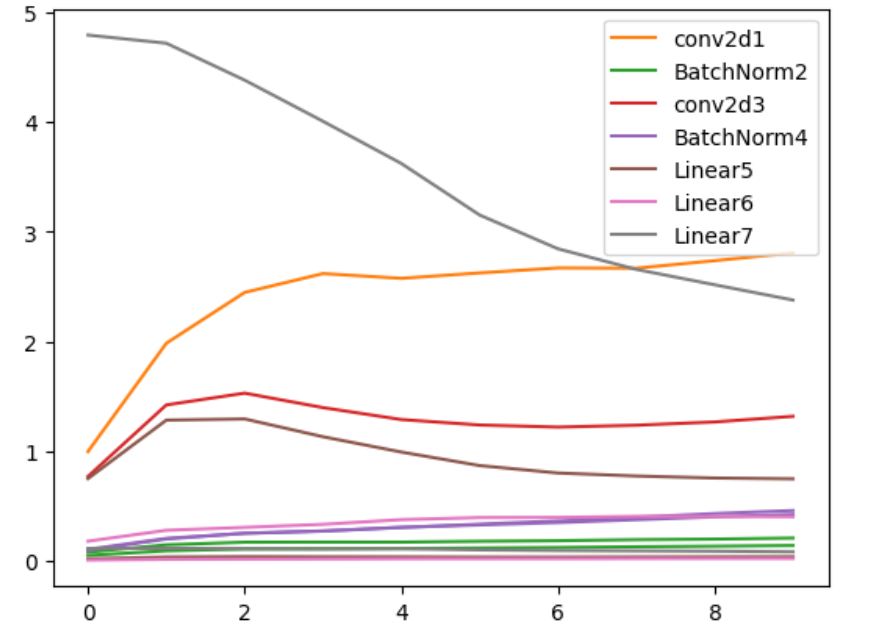

* the final layer start with the highest gradient as the prediction initialy random and the gradient come directly from the loss function. as the training continue the predictions become more confident so the gradient decreas
* the first layer initially receive small gradient as it the upstream gradient has to travel through noisy random routs that will distruct it, but as the network learns, the weights matrices align with the data and the gradient pass become clearer, at the end of convergence the gradient will shrink to 0 and the loss decrease

**use a data_augmenation technique**:
avg train loss: avg train loss: 0.9076 |avg val loss: 0.9270
* without any regularization ( only the batch normalization + pooling regularization effect)
* when i increase the batch size it start overfitting earlier an that comes down that the variation between batchs' statistices decrease and the stochastic noise also decrease which make the model have a bigger chance to fall into local minima.

**the underfitting result from:**
* forgetting to add activations after each MLP linear layer, the data augmentation like color jitter and RandomResizedcrop make the mession difcult for the model with capacity of 20 filter in the firts layer and 40 filter in the second layer.
* i will increase it to 32 and 64, remove randomcrop and add activation layer after each linear one, and i achieved **avg train loss: 0.59 |avg val loss: 0.56**
* use L2 norm with lambda of 1e-6 i achieved **avg train loss: 0.56 |avg val loss: 0.52**
* with padding = 2 in the first conv layer and adams_W that separet the weight decay from the update step i achieved: 

In [ ]:
array = torch.tensor([[1,2,3]])
array.repeat_interleave(2, dim = 1)
